# Part 2: The Wine Dataset

The Wine dataset is a commonly used dataset in machine learning and data analysis, primarily for classification tasks. It represents the results of a chemical analysis of wines originating from three different grape varieties (classes). Each class corresponds to a different type of wine. The dataset contains a set of features derived from this chemical analysis.

- Number of Classes: 3 (representing three different types of wines)
- Number of Samples: 178
- Number of Features: 13 (chemical attributes)

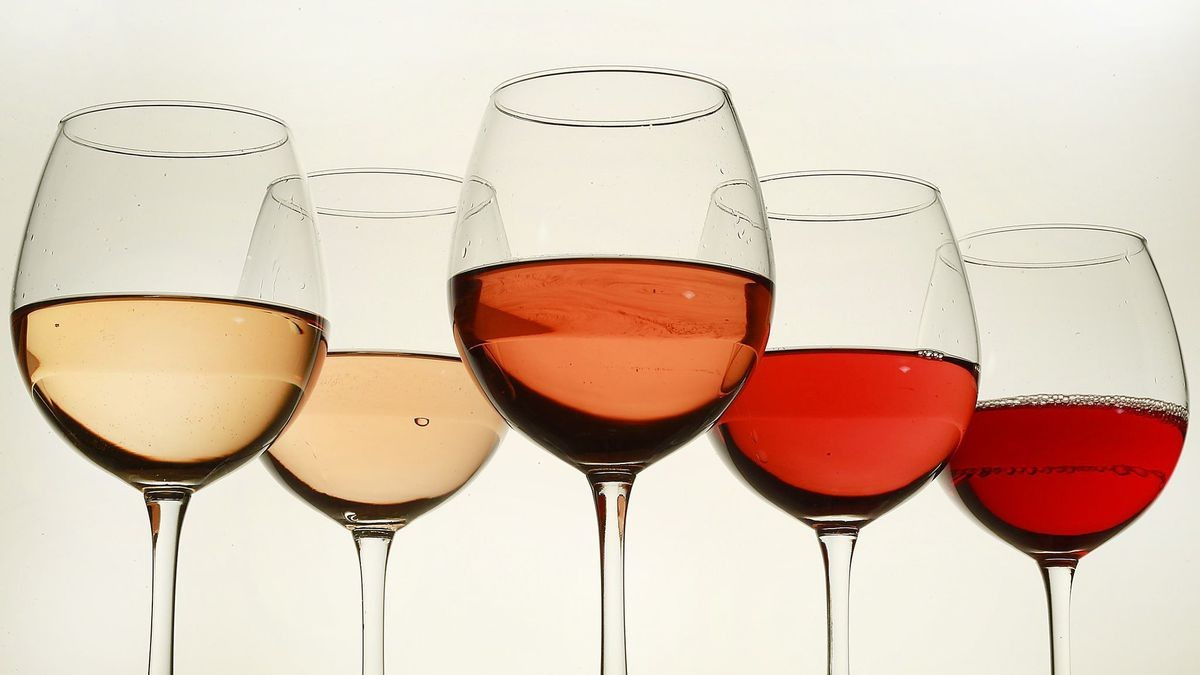

Let's now repeat the process with this new dataset.

In [1]:
from sklearn import datasets

# Load the Wine dataset
wine = datasets.load_wine()

# Extract the features (X) and target labels (y)
X = wine.data
y = wine.target

In [2]:
wine_df.head()

NameError: name 'wine_df' is not defined

The plots we did before can be easily done using **seaborn**, a fantastic visualization library. Investigate how we can use the `pairplot` [function](https://seaborn.pydata.org/generated/seaborn.pairplot.html) to create a plot using the dataframe we just created.

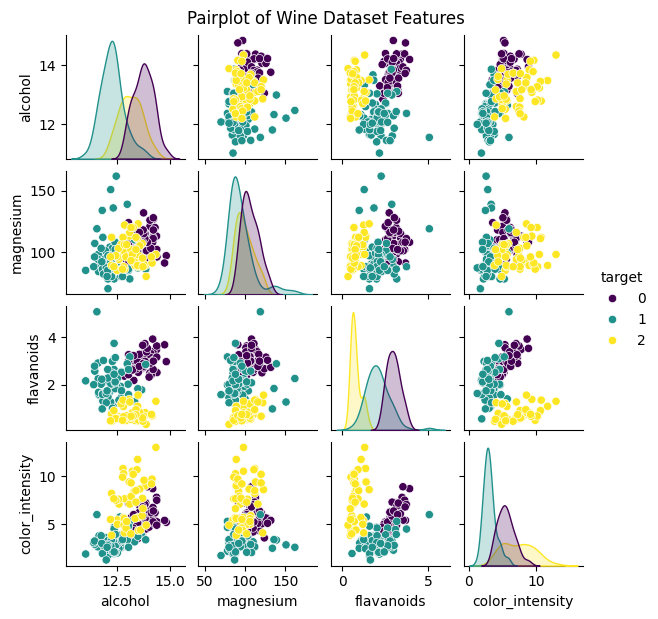

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(wine_df, hue='target',
             palette='viridis',
             diag_kind='kde',
             x_vars=['alcohol', 'magnesium', 'flavanoids', 'color_intensity'],
             y_vars=['alcohol', 'magnesium', 'flavanoids', 'color_intensity'],
             height=1.5
             )
plt.suptitle('Pairplot of Wine Dataset Features', y=1.02)
plt.show()

In [4]:
from sklearn import datasets
# Load the Wine dataset
wine = datasets.load_wine()
X = wine.data
y = wine.target


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
print(X.shape, y.shape)
print(X_train.shape, X_test.shape)

(178, 13) (178,)
(124, 13) (54, 13)


In [6]:
## use a random forest classifier to identify the wines
## Get the accuracy of your model

from sklearn.ensemble import RandomForestClassifier

bosc = RandomForestClassifier(n_estimators=100, random_state=0)
bosc.fit(X_train, y_train)
print(bosc.score(X_train, y_train))
print(bosc.score(X_test, y_test))



1.0
0.9814814814814815


[[13  0  0]
 [ 0 24  0]
 [ 0  0 17]]


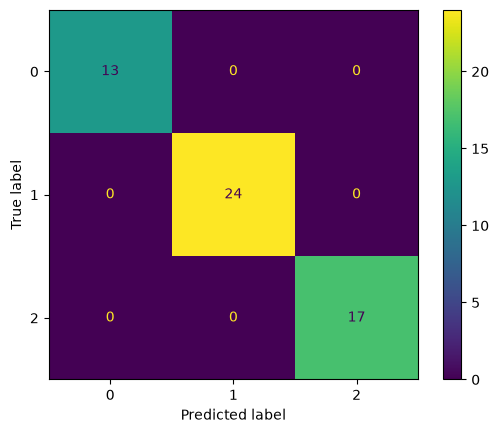

In [13]:
## Display the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

y_pred = bosc.predict(X_test)

print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

Great! Now that we trained the model, let's see if training a model with less features afects the model. We will use the following function: [SelectKBest](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html). It has to be used as any other sklearn model. You can use the functions `.fit` and `.transform` to train and transform data.




In [7]:
## Use Select KBest to select N amount of features.
from sklearn.feature_selection import SelectKBest

feature_selector = SelectKBest(k=4) # Seleccionem els 4 millors
feature_selector.fit(X_train, y_train)

X_train_4 = feature_selector.transform(X_train)     # train només amb les 4 columnes triades
X_test_4 = feature_selector.transform(X_test)  

print(X_train_4,X_test_4)

[[1.237e+01 5.700e-01 1.820e+00 5.200e+02]
 [1.200e+01 1.250e+00 2.650e+00 4.500e+02]
 [1.234e+01 2.110e+00 3.380e+00 4.380e+02]
 [1.270e+01 2.550e+00 3.130e+00 4.630e+02]
 [1.216e+01 1.690e+00 2.260e+00 4.950e+02]
 [1.305e+01 1.590e+00 2.010e+00 5.150e+02]
 [1.420e+01 3.390e+00 2.850e+00 1.450e+03]
 [1.222e+01 2.040e+00 3.020e+00 3.120e+02]
 [1.439e+01 2.520e+00 3.580e+00 1.290e+03]
 [1.422e+01 3.000e+00 3.310e+00 9.700e+02]
 [1.236e+01 9.200e-01 1.580e+00 5.200e+02]
 [1.311e+01 3.180e+00 3.180e+00 5.020e+02]
 [1.204e+01 1.750e+00 2.570e+00 5.800e+02]
 [1.377e+01 2.790e+00 2.930e+00 1.375e+03]
 [1.340e+01 7.500e-01 1.560e+00 7.500e+02]
 [1.233e+01 1.850e+00 2.310e+00 7.500e+02]
 [1.327e+01 6.900e-01 1.560e+00 8.350e+02]
 [1.296e+01 7.000e-01 1.750e+00 6.750e+02]
 [1.305e+01 3.000e+00 3.350e+00 8.850e+02]
 [1.260e+01 1.360e+00 2.770e+00 5.620e+02]
 [1.483e+01 2.980e+00 2.850e+00 1.045e+03]
 [1.285e+01 6.000e-01 2.110e+00 5.700e+02]
 [1.287e+01 6.500e-01 1.860e+00 6.250e+02]
 [1.356e+01

Let's train a classifier with the selected features

In [12]:
# Train classifier with selected features
from sklearn.ensemble import RandomForestClassifier

bosc_4 = RandomForestClassifier(n_estimators=100, random_state=0)
bosc_4.fit(X_train_4, y_train)
print(bosc_4.score(X_train_4, y_train))
print(bosc_4.score(X_test_4, y_test))


1.0
0.8888888888888888


[[21  0  0]
 [ 1 19  1]
 [ 0  4  8]]


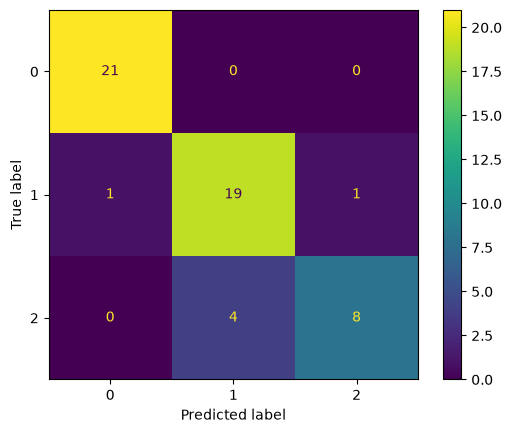

In [ ]:
## Display the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

y_pred_4 = bosc_4.predict(X_test_4)

print(confusion_matrix(y_test, y_pred_4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_4)

In [25]:
import numpy as np

# Get a boolean mask of selected features
selected_feature_mask = feature_selector.get_support()

# Get the names of the selected features
selected_feature_names = np.array(wine.feature_names)[selected_feature_mask]

print(selected_feature_names)

['alcohol' 'flavanoids' 'od280/od315_of_diluted_wines' 'proline']


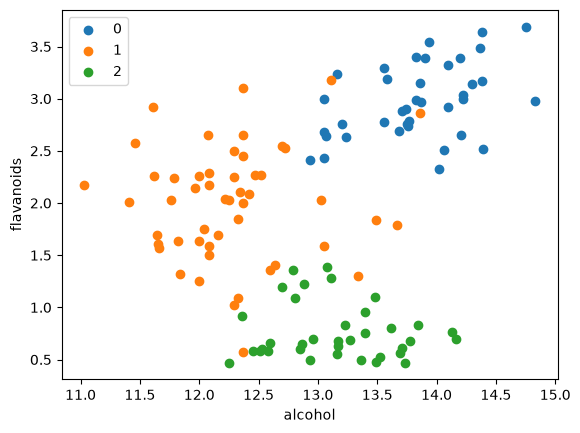

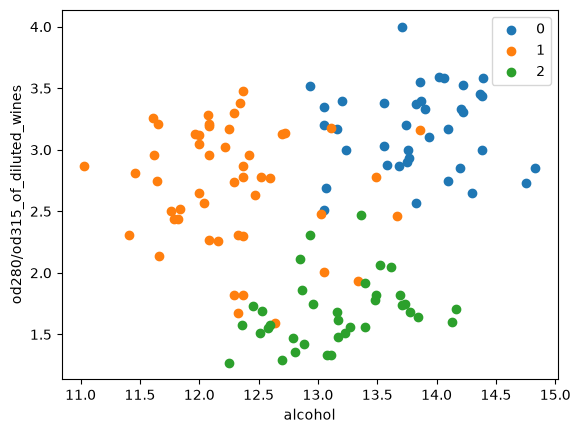

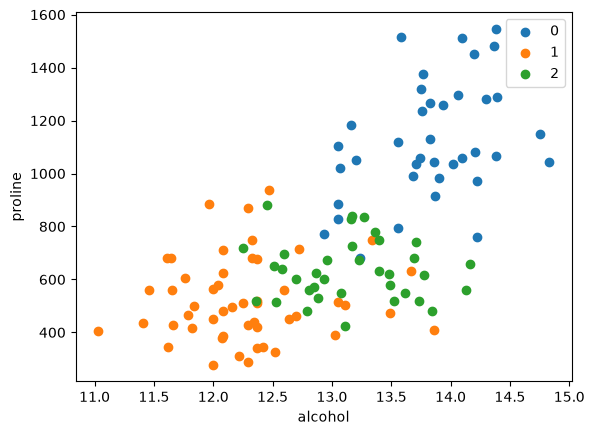

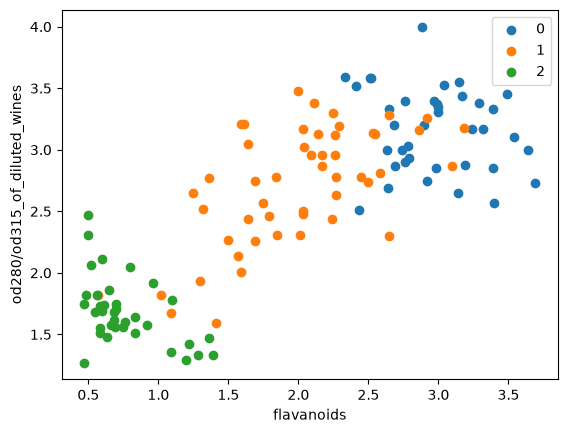

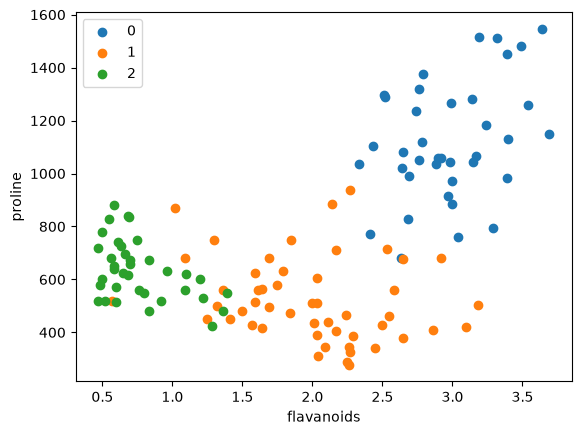

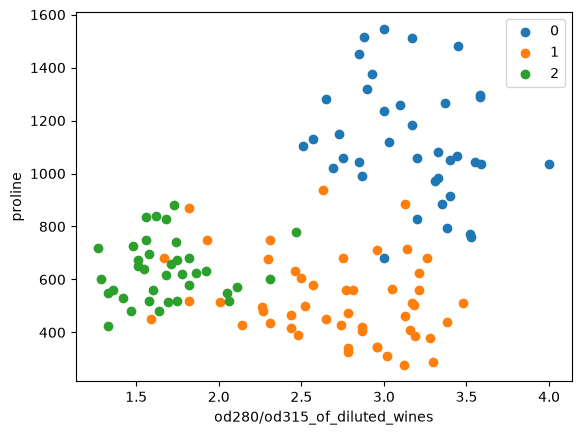

In [27]:
import matplotlib.pyplot as plt
import numpy as np


for i in range(4):
    for j in range(i+1,4):
        for classe in np.unique(y_train):
            mask = (y_train == classe)
            plt.scatter(X_train_4[mask, i], X_train_4[mask, j], label=classe)

        plt.xlabel(selected_feature_names[i])
        plt.ylabel(selected_feature_names[j])
        plt.legend()
        plt.show()

['alcohol' 'flavanoids' 'od280/od315_of_diluted_wines' 'proline']
